# Do the Reasons Students Give Match How Much They Use AI?

## Idea

We want to understand why some students use AI more than others. The survey asked students how much different reasons keep them from using AI. Some reasons come from the student ("I want to learn the material myself," "I don't trust its answers") and one comes from the class ("My class rules don't allow it").

We expect that students who say a reason holds them back more will use AI less. We want to see if that is true for all three reasons.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../../data/uncleaned_data.csv")

# The answers use a curly apostrophe (’). Swap it for a normal one (') so we can type the answers exactly.
df = df.replace("’", "'", regex=True)

## Analysis

**Step 1: AI-reliance score.** The survey asked how often students use AI for 8 different tasks (reviewing slides, coding assignments, asking questions, etc.). We turn each answer into a number and average them, so each student gets one score:

| Answer | Number |
|---|---|
| I don't use AI for this | 0 |
| I use it rarely | 1 |
| I use it sometimes | 2 |
| I use it very often | 3 |

So a score of 0 means the student never uses AI for these tasks, and 3 means they use it very often for all of them.

In [2]:
# The 8 "How often do you use AI for the following: [task]" columns
ai_cols = [c for c in df.columns if c.startswith("How often do you use AI for the following:")]

to_number = {
    "I don't use AI for this": 0,
    "I use it rarely": 1,
    "I use it sometimes": 2,
    "I use it very often": 3,
}

# Convert each column to numbers. Anything not in the dictionary (blank, "Prefer not to answer") becomes NaN.
numbers = pd.DataFrame()
for col in ai_cols:
    numbers[col] = df[col].map(to_number)

# Average the 8 numbers for each student (NaNs are skipped)
df["reliance_score"] = numbers.mean(axis=1)

print("Students with a score:", df["reliance_score"].notna().sum())

Students with a score: 78


**Step 2: Group students by each reason.** For each of the three reasons, we split students by how much they said it keeps them from using AI. "Not at all" is combined with "A little" because only a few students picked "Not at all."

**Step 3: Plot.** One panel per reason, one violin per group. The height is the AI-reliance score. If the violins go **down** from left to right, students who feel that reason more strongly use AI less.

I want to learn the material myself
   Not at all / A little: 2.31
   Somewhat: 1.75
   A lot: 1.56

I don't trust its answers
   Not at all / A little: 2.06
   Somewhat: 1.75
   A lot: 0.88

My class rules don't allow it
   Not at all / A little: 1.88
   Somewhat: 1.75
   A lot: 1.75



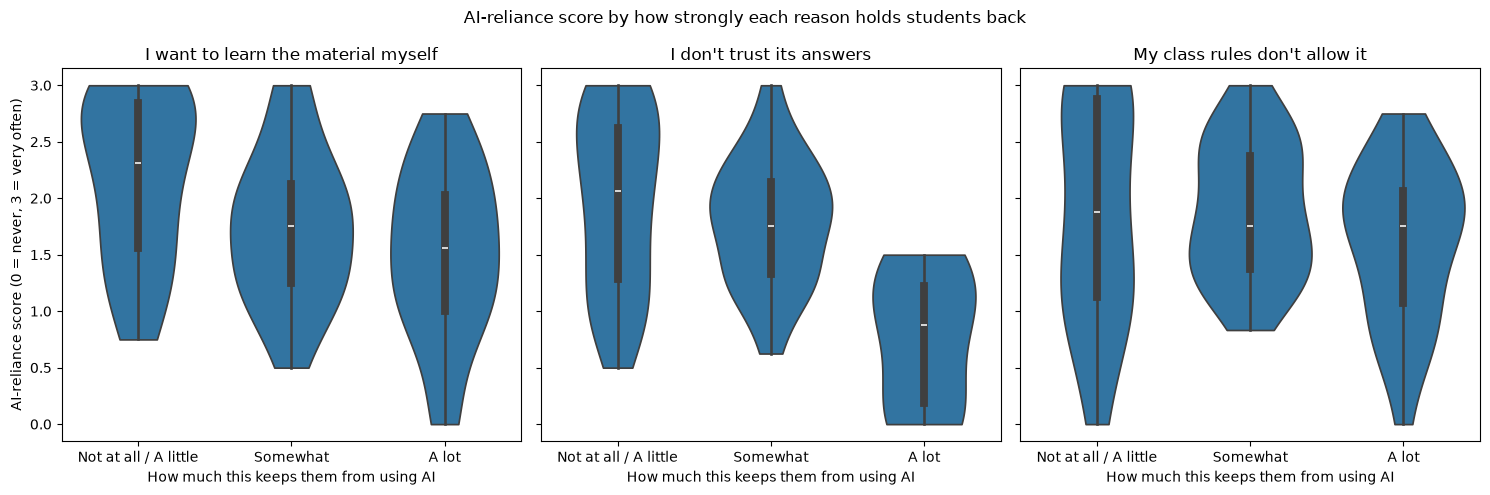

In [3]:
# Panel title -> the column for that reason
reasons = {
    "I want to learn the material myself": [c for c in df.columns if "learn the material myself" in c][0],
    "I don't trust its answers":           [c for c in df.columns if "trust its answers" in c][0],
    "My class rules don't allow it":       [c for c in df.columns if "class rules" in c][0],
}

combine = {"Not at all": "Not at all / A little", "A little": "Not at all / A little"}
order = ["Not at all / A little", "Somewhat", "A lot"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

i = 0
for title, col in reasons.items():
    groups = df[col].replace(combine)

    sns.violinplot(x=groups, y=df["reliance_score"], order=order, cut=0, ax=axes[i])
    axes[i].set_title(title)
    axes[i].set_xlabel("How much this keeps them from using AI")

    # Print the median score for each group
    print(title)
    for g in order:
        median = df.loc[groups == g, "reliance_score"].median()
        print(f"   {g}: {median:.2f}")
    print()

    i += 1

axes[0].set_ylabel("AI-reliance score (0 = never, 3 = very often)")
fig.suptitle("AI-reliance score by how strongly each reason holds students back")
plt.tight_layout()
plt.show()

**What the plot shows (median AI-reliance score):**

| Reason | Not at all / A little | Somewhat | A lot |
|---|---|---|---|
| I want to learn the material myself | 2.31 | 1.75 | 1.56 |
| I don't trust its answers | 2.06 | 1.75 | 0.88 |
| My class rules don't allow it | 1.88 | 1.75 | 1.75 |

- **Learn it myself:** the violins go down. The more students want to learn the material themselves, the less they use AI.
- **Don't trust it:** the violins also go down, and drop the most. (Only 8 students said "A lot," so that group is small.)
- **Class rules:** the violins stay about the same. Students who say rules hold them back use AI about as much as everyone else.

## Conclusion

We expected all three reasons to go with less AI use, but only two did. The reasons that come from the student, wanting to learn the material and not trusting AI's answers, go with noticeably lower AI use. The reason that comes from the class, rules against AI, does not.

So, taking students' answers at face value, part of why some students use AI more than others is their own beliefs, not the rules they are given. Even so, the students who care most about learning the material still use AI somewhat (median between "rarely" and "sometimes"), so personal reasons lower AI use but don't stop it.